##### Master Degree in Computer Science and Data Science for Economics and Health

# Neural language models: approximating the probability of the next word

### Prof. Alfio Ferrara

## Introduction

The previous notebook ended with a limit that no smoothing can remove. A model built by counting treats each context as a symbol on its own: it knows what follows `lemon`, it knows what follows `lime`, and what it learns about one does not help with the other. It also pays a price that grows exponentially with the memory, since there are $V^k$ possible contexts of $k$ words. The interpolation of the orders is a clever way to estimate the probabilities of what we have not seen, but it remains an estimate **made by counting**.

Here we change the idea. We stop estimating $P(w \mid \text{context})$ one context at a time and we **approximate it with a function**: a neural network that takes the $k$ previous words, turns each of them into a vector (an *embedding*, as in the notebooks on Word2Vec), combines the vectors, and returns a distribution over the next word. The parameters of the function are shared by all the contexts, so what is learned in one place is used in all the others. This is the idea of Bengio, Ducharme, Vincent and Jauvin, *A Neural Probabilistic Language Model* (JMLR, 2003), which is the first neural language model and the bridge between the statistical and the neural approaches.

We already have all the ingredients. The softmax and the cross-entropy loss are the ones of the notebook on the next word as a classification, the layer with ReLU is the one of the notebook on hidden representations, and the embeddings are the ones of Word2Vec. What changes is the input, which is now a **window of words**.

The plan of the notebook:

1. a toy example in which the network generalizes where the counts cannot;
2. two ways of combining the words of the window, the average (as in the CBOW of Word2Vec) and the concatenation (as in Bengio), compared with the n-grams of the previous notebook **at the same memory**;
3. what the network does better, and a way to use together the network and the counts;
4. what the network cannot do: a window of fixed size, and a text with no plan, which is the starting point of the last part of the course.

We use the **recipes** (the instructions, as in the previous notebooks), with the same split of the documents (80% training, 10% validation, 10% test), the same vocabulary of 4,000 words and the same perplexity, so that the numbers can be compared with the ones of the previous notebook. The plots of films are left out of this notebook, to keep the training times short.

## A toy example: generalizing by similarity

We start from an invented world, in the spirit of the previous notebooks: four people, four drinks, four foods and sentences of three words. `anna` and `sara` are two people who drink (they `drink`, `buy` or `like` drinks), `luca` and `marco` are two people who eat (they `eat`, `buy` or `like` foods). The two pairs behave in the same way, and the only difference between `anna` and `sara` is that we never see `sara` buying or liking anything: in the training set `sara` only **drinks**. The context `sara buys` never appears.

Then we ask the question: after `sara buys`, is the next word a drink or a food? A person who knows that `sara` and `anna` are used in the same way answers without doubt. Let us see what the counts and the network answer. The network has a window of two words, embeddings of size 4, a layer of 16 neurons with ReLU, and it is trained on the 600 sentences (we repeat it with five initializations, because with a network so small the result can change from one to another).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from collections import Counter

from nlp import lm
from nlp.ngram import NGramModel

drinks = ["coffee", "tea", "milk", "juice"]
foods = ["bread", "pasta", "rice", "cake"]
drinkers, eaters = ["anna", "sara"], ["luca", "marco"]

rng = np.random.default_rng(0)
toy_sentences = []
for _ in range(600):
    person = str(rng.choice(drinkers + eaters))
    if person in drinkers:
        verb, thing = str(rng.choice(["drinks", "buys", "likes"])), str(rng.choice(drinks))
    else:
        verb, thing = str(rng.choice(["eats", "buys", "likes"])), str(rng.choice(foods))
    if person == "sara" and verb != "drinks":          # sara is never seen buying or liking anything
        verb, thing = "drinks", str(rng.choice(drinks))
    toy_sentences.append([person, verb, thing])

toy_words = ["<unk>", "<s>", "</s>"] + sorted({w for s in toy_sentences for w in s})
toy_ids = [tuple(toy_words.index(w) for w in ["<s>"] + s + ["</s>"]) for s in toy_sentences]
print("sentences of sara:", sum(s[0] == "sara" for s in toy_sentences), "| sentences that begin with 'sara buys':",
      sum(s[:2] == ["sara", "buys"] for s in toy_sentences))

def train_toy(seed, k=2, d=4, hidden=16, epochs=300):
    X, y, _ = lm.windows(toy_ids, k)
    X, y = torch.as_tensor(X), torch.as_tensor(y)
    torch.manual_seed(seed)
    model = lm.Window(len(toy_words), k, d, hidden, "concat")
    optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
    for _ in range(epochs):                       # all the 1,800 positions at each step
        loss = F.cross_entropy(model(X), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model

def network_drink(model, context):
    p = torch.softmax(model(torch.tensor([[toy_words.index(w) for w in context]])), dim=-1)[0].detach().numpy()
    return sum(p[toy_words.index(w)] for w in drinks)

def counts_drink(n, context):
    p = NGramModel(n, len(toy_words)).fit(toy_ids).distribution([toy_words.index(w) for w in context], method="mle")
    return np.nan if p.sum() == 0 else sum(p[toy_words.index(w)] for w in drinks)

toy_nets = [train_toy(seed) for seed in range(5)]
rows = {}
for context in [("anna", "buys"), ("luca", "buys"), ("sara", "buys")]:
    values = [network_drink(m, context) for m in toy_nets]
    rows[" ".join(context)] = {"counts, two words of context": counts_drink(3, context),
                              "counts, only the last word": counts_drink(2, context[1:]),
                              "network: mean of 5 initializations": np.mean(values),
                              "network: minimum": np.min(values), "network: maximum": np.max(values)}
pd.DataFrame(rows).T.rename_axis("P(next word is a drink | context)").style.format("{:.2f}", na_rep="never seen")

sentences of sara: 163 | sentences that begin with 'sara buys': 0


,"counts, two words of context","counts, only the last word",network: mean of 5 initializations,network: minimum,network: maximum
P(next word is a drink | context),,,,,
anna buys,1.00,0.31,1.00,1.00,1.00
luca buys,0.00,0.31,0.00,0.00,0.00
sara buys,never seen,0.31,0.99,0.96,1.00


The counts have nothing to say about `sara buys`: the context never occurs in the 600 sentences, so with two words of context there is no estimate at all, and the only thing left is to fall back on the last word, `buys`. After `buys` the next word is a drink in 31% of the cases, which is the average over the people who buy: it knows nothing about who is buying. The network answers 0.99 on average (between 0.96 and 1.00 with the five initializations). For the contexts that it has seen (`anna buys`, `luca buys`) it gives the same answers as the counts, 1.00 and 0.00. Nobody told the network that `sara` is like `anna`.

In [2]:
def cosine(model, a, b):
    E = model.embed.weight.detach().numpy()
    u, v = E[toy_words.index(a)], E[toy_words.index(b)]
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))

pd.DataFrame({"initialization": range(5),
              "P(drink | sara buys)": [network_drink(m, ("sara", "buys")) for m in toy_nets],
              "cosine(sara, anna)": [cosine(m, "sara", "anna") for m in toy_nets],
              "cosine(sara, luca)": [cosine(m, "sara", "luca") for m in toy_nets]}).set_index("initialization").style.format("{:.2f}")

,P(drink | sara buys),"cosine(sara, anna)","cosine(sara, luca)"
initialization,,,
0,0.99,0.66,0.25
1,1.00,0.83,-0.25
2,0.96,0.28,-0.82
3,1.00,0.59,0.20
4,1.00,0.65,-0.50


Why does it work? The network describes each word with **one vector for all the contexts** in which it appears. `sara` appears in the same contexts as `anna` (after `<s>` the next word is `drinks`, after `sara drinks` it is a drink), and in different ones from `luca` and `marco`, who are followed by `eats`. The embeddings reflect it: in all the five initializations the cosine between `sara` and `anna` (from 0.28 to 0.83) is higher than the one between `sara` and `luca` (from -0.82 to 0.25). The layer that follows the embeddings then treats `sara buys` as it treats `anna buys`, without ever having seen it.

This is a construction, not evidence: it shows the mechanism, and the real corpora will tell us how much of it survives. It is also not guaranteed: in a trial with embeddings of size 2 (not in this notebook) two initializations out of five gave the wrong answer, and here the cosine changes a lot from one initialization to another (0.28 for the one that answers 0.96).

## Two ways of looking at a window of words

The network of the toy example is the simplest case of the family that we use in the rest of the notebook. Given the $k$ words that precede the one to be predicted, $w_{t-k}, \dots, w_{t-1}$, the network:

1. replaces each word with its **embedding**, a vector of $d$ numbers taken from a table with a row for each word of the vocabulary (the same table for all the positions of the window);
2. **combines** the $k$ vectors in a single vector $x$;
3. optionally passes $x$ through a layer of neurons with ReLU, $h = \mathrm{ReLU}(W_1 x + b_1)$;
4. computes a score for each word of the vocabulary and turns the scores into probabilities with the softmax, $P(w \mid \text{window}) = \mathrm{softmax}(W_2 h + b_2)$.

The training is the one of the notebook on the next word: we minimize the cross-entropy of the true next word with Adam, on minibatches, and we keep the weights of the epoch with the lowest loss on the validation set (early stopping).

The step 2 can be done in two ways, and the choice is the heart of the model:

- **average**: $x = \frac{1}{k}\sum_{j=1}^{k} e_{w_{t-j}}$. It is the CBOW of Word2Vec, with the difference that here we only use the words *before* the one to be predicted (we cannot see the future when we write). The vector $x$ has size $d$ whatever $k$ is, but **the order of the words is lost**: `dog bites man` and `man bites dog` have the same input;
- **concatenation**: $x = [e_{w_{t-k}}; \dots; e_{w_{t-1}}]$, a vector of size $kd$. Each position of the window has its own block of weights in the next layer, so the model knows *which* word comes in which position. This is the model of Bengio et al. (2003).

In both cases the number of parameters grows **linearly** with $k$ (at most by $d$ times the size of the next layer for each new word), instead of exponentially as the number of contexts of an n-gram. We always use the layer with ReLU, except in one comparison with the average alone (the CBOW of the previous notebook has none), and the same sizes everywhere: embeddings of $d = 64$, a layer of 128 neurons. They are one configuration, chosen without a search: we do not try to make the network win.

In [3]:
def prepare(documents):
    train_docs, validation_docs, test_docs = lm.split_documents(documents)
    vocabulary = lm.Vocabulary(train_docs, size=4000)
    sentences = lambda docs: [tuple(vocabulary.encode(s)) for doc in docs for s in doc]    # <s> w1 ... wn </s>, as ids
    return vocabulary, sentences(train_docs), sentences(validation_docs), sentences(test_docs)

vocabulary, train, validation, test = prepare(lm.load_recipes())
V = len(vocabulary)

# The examples of the network are the positions of the n-gram models with n = k + 1: same words to predict, same memory
for k in (1, 2, 3, 4):
    X, y, _ = lm.windows(validation, k)
    Xn, yn = NGramModel(k + 1, V).positions(validation)
    assert (X == Xn).all() and (y == yn).all()
print(f"{len(lm.windows(train, 3)[1]):,} training examples, {len(lm.windows(validation, 3)[1]):,} validation examples")

# The counting models of the previous notebook: interpolation of the orders, weights fitted on the validation set
ngrams = {n: NGramModel(n, V).fit(train) for n in range(1, 6)}
ngram_perplexity = {n: ngrams[n].perplexity(validation, method="interpolation", weights=ngrams[n].fit_weights(validation)) for n in range(2, 6)}
print({n: round(v, 1) for n, v in ngram_perplexity.items()})

920,631 training examples, 115,361 validation examples


{2: 64.4, 3: 50.2, 4: 49.6, 5: 49.6}


## The network against the n-grams, at the same memory

A network with a window of $k$ words and an n-gram model with $n = k + 1$ see **the same words** to predict the next one: the comparison is between two ways of using the same information. For each $k$ from 1 to 4 we train three networks: the average of the embeddings, the average followed by a layer with ReLU, and the concatenation followed by a layer with ReLU. We compare them with the n-gram model with interpolation of the previous notebook (the same numbers). The perplexity is the one of the validation set, at the epoch with the lowest validation loss.

**A note on the execution time.** Training the networks takes some minutes (about 30 seconds for each one), and the notebook trains more than twenty. To save time the trained networks are **saved in the folder `models/L0.8`, outside the repository** (one level above it), and loaded from there when they exist, so that the notebook can be run again in a minute. This is only a matter of execution time: the saved files contain nothing that the code of the notebook does not produce. If you change the data or the settings of the networks, delete the folder and they will be trained again.

In [4]:
import os, time

CACHE = "../../models/L0.8"          # outside the repository: the trained networks, saved only to save execution time

def fit_or_load(label, k, combine, hidden, seed=0):
    path = f"{CACHE}/recipes-{combine}-hidden{hidden}-k{k}-seed{seed}.pt"
    return lm.fit_window(V, k, train, validation, combine=combine, hidden=hidden, seed=seed, cache=path)

variants = {"average": ("mean", 0), "average + ReLU": ("mean", 128), "concatenation + ReLU": ("concat", 128)}
networks, histories = {}, {}
start = time.time()
for label, (combine, hidden) in variants.items():
    for k in (1, 2, 3, 4):
        networks[label, k], histories[label, k] = fit_or_load(label, k, combine, hidden)
print(f"{time.time() - start:.0f} s")

def validation_perplexity(label, k):
    X, y, _ = lm.windows(validation, k)
    return float(np.exp(-lm.log_probabilities(networks[label, k], X, y).mean()))

def comparison_table():
    table = pd.DataFrame({label: {k: validation_perplexity(label, k) for k in (1, 2, 3, 4)} for label in variants})
    table.insert(0, "n-gram, interpolation (n = k + 1)", [ngram_perplexity[k + 1] for k in table.index])
    table["epoch of the best network"] = [networks["concatenation + ReLU", k].best_epoch for k in table.index]
    return table.rename_axis("k (words of memory)")

comparison_table().style.format({c: "{:.1f}" for c in ["n-gram, interpolation (n = k + 1)", *variants]} | {"epoch of the best network": "{:d}"})

0 s


,"n-gram, interpolation (n = k + 1)",average,average + ReLU,concatenation + ReLU,epoch of the best network
k (words of memory),,,,,
1,64.4,62.8,63.9,63.9,5
2,50.2,57.8,54.2,47.6,5
3,49.6,60.1,55.3,44.0,5
4,49.6,62.4,56.7,42.7,5


Reading the table by columns.

**Average.** With $k = 1$ the network is the table of scores $V \times V$ of the previous notebook factorized in two matrices (the embeddings and the output weights, of size 64), and it gets 62.8 on the validation set: better than the table with early stopping (68.4) and about the same as the bigram with interpolation (64.4), without any smoothing. When we add words to the average the perplexity gets **worse**: 57.8, 60.1 and 62.4 for $k = 2, 3, 4$ (54.2, 55.3, 56.7 with the layer of ReLU). The average puts all the words of the window in one vector without saying where each one is, and the more words are in it the less each one counts.

**Concatenation.** It improves with the memory: 63.9, 47.6, 44.0 and 42.7. (With $k = 1$ it is the same model as the average with the layer.) The n-gram with interpolation at the same memory gets 64.4, 50.2, 49.6 and 49.6: about the same at $k = 1$, and from $k = 2$ the network is better, by 2.6, 5.6 and 6.9 points, because it goes on improving where the n-gram stops (we saw that the fifth order has weight zero). The comparison between the average with the layer and the concatenation says that the advantage does not come from the ReLU: it comes from keeping **which word is in which position**.

These are the numbers of one initialization, each network at the epoch with the lowest validation loss (the last column: the fifth epoch for all the concatenations, the early stopping does its work). A check on the initializations follows.

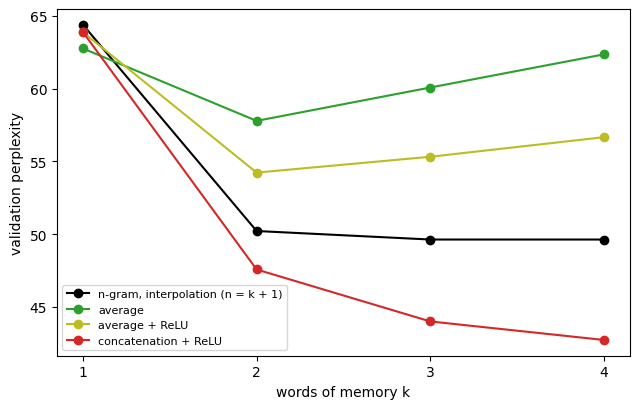

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
table = comparison_table()
ax.plot(table.index, table["n-gram, interpolation (n = k + 1)"], marker="o", color="black", label="n-gram, interpolation (n = k + 1)")
for label, color in zip(variants, ["tab:green", "tab:olive", "tab:red"]):
    ax.plot(table.index, table[label], marker="o", color=color, label=label)
ax.set_xlabel("words of memory k")
ax.set_ylabel("validation perplexity")
ax.set_xticks([1, 2, 3, 4])
ax.legend(fontsize=8)
plt.tight_layout()

The figure shows the same thing: the concatenation (red) is below the n-gram (black) from $k = 2$ and keeps going down, while the two averages (green and olive) go up with the memory.

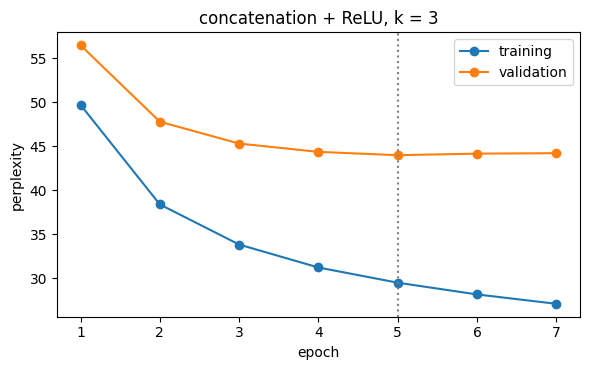

In [6]:
h = pd.DataFrame(histories["concatenation + ReLU", 3]).set_index("epoch")
c = np.exp(h[["train", "validation"]])
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(c.index, c["train"], marker="o", label="training")
ax.plot(c.index, c["validation"], marker="o", label="validation")
ax.axvline(networks["concatenation + ReLU", 3].best_epoch, color="gray", linestyle=":")
ax.set_title("concatenation + ReLU, k = 3")
ax.set_xlabel("epoch")
ax.set_ylabel("perplexity")
ax.set_xticks(c.index)
ax.legend()
plt.tight_layout()

The curves show what the early stopping does. The perplexity on the training set keeps falling (29.5 at the fifth epoch, and the network goes on to 27 in the seventh), and the one on the validation set stops at the fifth epoch (44.0) and then goes up a little: the network overfits, as the table of the previous notebook did, though with a much smaller gap (the parameters of the network do not grow with $V^2$).

In [7]:
X, y, _ = lm.windows(validation, 3)
values = [validation_perplexity("concatenation + ReLU", 3)]
for seed in (1, 2):
    model, _ = fit_or_load("concatenation + ReLU", 3, "concat", 128, seed=seed)
    values.append(float(np.exp(-lm.log_probabilities(model, X, y).mean())))
pd.DataFrame({"concatenation + ReLU, k = 3": values, "n-gram, n = 4": ngram_perplexity[4]}, index=["seed 0", "seed 1", "seed 2"]).T.style.format("{:.1f}")

,seed 0,seed 1,seed 2
"concatenation + ReLU, k = 3",44.0,44.0,44.1
"n-gram, n = 4",49.6,49.6,49.6


Seed 0 is the one of the table. With three initializations the perplexity of the concatenation with $k = 3$ is 44.0, 44.0 and 44.1: the variation is of one tenth of a point, much less than the distance from the n-gram with $n = 4$ (5.6 points). The comparison does not depend on the initialization. It says nothing on the **configuration** (embeddings of 64, a layer of 128, learning rate 0.005): we did not explore it.

### Does the network use the order of the words?

The average cannot, by construction. The concatenation can, and we check that it does with a **permutation test**: for each position of the validation set we shuffle the $k = 3$ words of the window at random (the words are the same, the order is lost) and we compute the perplexity again with the networks already trained. If the model used only *which* words are in the window and not *where*, the perplexity would not change.

In [8]:
def shuffled(X, seed=0):
    order = np.argsort(np.random.default_rng(seed).random(X.shape), axis=1)
    return np.take_along_axis(X, order, axis=1)

X, y, _ = lm.windows(validation, 3)
Xs = shuffled(X)
rows = {}
for label in variants:
    model = networks[label, 3]
    rows[label] = {"original order": np.exp(-lm.log_probabilities(model, X, y).mean()),
                   "words of the window shuffled": np.exp(-lm.log_probabilities(model, Xs, y).mean())}
pd.DataFrame(rows).T.rename_axis("network (k = 3)").style.format("{:.1f}")

,original order,words of the window shuffled
network (k = 3),,
average,60.1,60.1
average + ReLU,55.3,55.3
concatenation + ReLU,44.0,299.1


The average gives the same perplexity by construction (60.1 and 55.3): the average of three vectors does not change if we shuffle them, and the check just confirms it. The concatenation falls apart: from 44.0 to 299.1, about the perplexity of the frequency of the words alone (304.6 on the validation set, previous notebook). A network that has learned to trust each position, with the words in the wrong places, is as bad as a model that ignores the context. So the concatenation uses the order, and this is what the average loses.

In [9]:
vocabulary_size = 4000
rows = {}
for k in (1, 2, 3, 4, 8):
    network = lm.Window(vocabulary_size, k, 64, 128, "concat")
    rows[k] = {"parameters of the network": sum(p.numel() for p in network.parameters())}
    if k <= 4:
        rows[k]["different pairs (context, word) in the recipes"] = len(ngrams[k + 1].pairs[k][0])
    rows[k]["possible pairs, V^(k+1)"] = float(vocabulary_size) ** (k + 1)
pd.DataFrame(rows).T.rename_axis("k").style.format({"parameters of the network": "{:,.0f}", "different pairs (context, word) in the recipes": "{:,.0f}",
                                                     "possible pairs, V^(k+1)": "{:.1e}"}, na_rep="")

,parameters of the network,"different pairs (context, word) in the recipes","possible pairs, V^(k+1)"
k,,,
1,"780,320","119,001",1.6e+07
2,"788,512","342,170",6.4e+10
3,"796,704","515,670",2.6e+14
4,"804,896","606,532",1.0e+18
8,"837,664",,2.6e+32


The number of parameters of the network hardly depends on $k$: 780,320 for $k = 1$ and 8,192 more for each word added to the window (the block of $d \times h = 64 \times 128$ weights), up to 837,664 for $k = 8$. The pairs (context, word) that are possible are $V^{k+1}$, from $1.6 \times 10^7$ to $10^{18}$ for $k = 4$, and the ones that the training set actually contains are 119,001, 342,170, 515,670 and 606,532: they are the entries that an n-gram has to keep, and they grow with the corpus.

We should not read it as a saving of memory: at these sizes the network has more parameters than the n-gram has entries (780,320 against 119,001 for $k = 1$, 804,896 against 606,532 for $k = 4$). The difference is in **how the parameters are used**: the n-gram has one entry for each pair and the network shares its parameters among all the contexts, as in the toy example.

## Where the network helps

The perplexity is an average over all the positions, and it hides what we want to know: does the network do better **where the counts have nothing to say**? We split the positions of the validation set in two groups, the ones whose context of $k = 3$ words occurs in the training set (the counts have something) and the ones whose context was never seen (the interpolation can only borrow from the shorter contexts), and we compute the perplexity of the two models separately. For the n-gram model we use $n = 4$ with the interpolation.

In [10]:
k = 3
ngram = ngrams[k + 1]
X, y = ngram.positions(validation)
p_ngram = ngram.probabilities(X, y, method="interpolation", weights=ngram.fit_weights(validation))
p_network = np.exp(lm.log_probabilities(networks["concatenation + ReLU", k], X, y))
seen = ngram.counts(X, y, k)[1] > 0
perplexity = lambda p, mask: float(np.exp(-np.log(p[mask]).mean()))
rows = {}
for label, mask in [("all positions", np.ones_like(seen)), ("context seen in training", seen), ("context never seen", ~seen)]:
    rows[label] = {"share of positions": mask.mean(), "n-gram (n = 4)": perplexity(p_ngram, mask), "network (k = 3)": perplexity(p_network, mask)}
pd.DataFrame(rows).T.style.format({"share of positions": "{:.1%}", "n-gram (n = 4)": "{:.1f}", "network (k = 3)": "{:.1f}"})

,share of positions,n-gram (n = 4),network (k = 3)
all positions,100.0%,49.6,44.0
context seen in training,72.5%,38.7,36.2
context never seen,27.5%,95.6,73.6


72.5% of the positions have a context of three words that occurs in the training set. There the network is a little better (36.2 against 38.7), as we expected, since the counts are reliable. On the other 27.5%, whose context was never seen, the difference is large: **73.6 against 95.6**, 23% less, in the positions where the interpolation can only borrow from the shorter contexts. Those positions are about a quarter of the total and give about 60% of the gain in the log of the perplexity (the difference between 49.6 and 44.0). The claim of the previous notebook, that the network can do what counting cannot, is confirmed where we expected it.

In [11]:
E = networks["concatenation + ReLU", 3].embed.weight.detach().numpy()
E = E / np.linalg.norm(E, axis=1, keepdims=True)

def neighbors(word, n=6):
    similarity = E @ E[vocabulary.index[word]]
    return ", ".join(vocabulary.words[i] for i in np.argsort(-similarity)[1:n + 1])

pd.Series({w: neighbors(w) for w in ["lime", "saucepan", "thyme", "oven", "bowl", "minutes", "stir", "chicken"]}, name="nearest embeddings").to_frame()

,nearest embeddings
lime,"lemon, clam, gills, orange, insides, candied"
saucepan,"skillet, evoo, celcius, age, pan, pile"
thyme,"medallion, capers, tarragon, mojo, parsley, ex..."
oven,"fryer, grill, degrees, tin, upright, aluminum"
bowl,"gradually, tablespoonfuls, frosting, shaken, t..."
minutes,"min, minute, seconds, mins, hour, hours"
stir,"whisk, swirl, toss, spin, mix, simmered"
chicken,"sausage, vermouth, beef, steak, salmon, hamburger"


We look at the nearest embeddings (cosine) of the first layer of the network with $k = 3$ for eight words that we have chosen. Two of them are the examples of the previous notebook: `lime` is near `lemon` and `orange`, `saucepan` near `skillet` and `pan`, the pairs that the counts could not use. The neighbors of `thyme` are herbs and condiments (`tarragon`, `parsley`, `capers`), those of `minutes` are `min`, `minute`, `seconds` and `hours`, `stir` is near `whisk`, `toss` and `mix`, `oven` near `fryer` and `grill`, `chicken` near other meats (`sausage`, `beef`, `steak`, `salmon`).

It does not always work. The neighbors of `bowl` (`gradually`, `tablespoonfuls`, `frosting`) are not other containers, and at the end of some lists there are words that are rare and uncertain (`evoo`, `celcius`, `medallion`). The embeddings are trained only to predict the next word, and the rare words have little to learn from. This is a reading of eight words, not a measure.

### Using the network and the counts together

The two models make mistakes in different places: the counts are very good when the context has been seen many times, the network when it has not. A natural idea, which is also in the paper of Bengio, is to use **both**: the probability of the mixture is $\lambda P_{\text{network}} + (1 - \lambda) P_{\text{n-gram}}$. It is the same idea as the interpolation of the orders of the previous notebook, applied to two models of different nature, and the weight $\lambda$ is fitted in the same way, with the expectation-maximization on the validation set. As we did for the orders, we check for optimism by fitting the weight on one half of the validation set and using it on the other half, and the other way round.

In [12]:
def fit_mixture(p_a, p_b, iterations=100):
    lam = 0.5
    for _ in range(iterations):
        a, b = lam * p_a, (1 - lam) * p_b
        lam = float((a / (a + b)).mean())
    return lam

def perplexity_of(p):
    return float(np.exp(-np.log(p).mean()))

ngram = ngrams[4]
X, y = ngram.positions(validation)
p_ngram = ngram.probabilities(X, y, method="interpolation", weights=ngram.fit_weights(validation))
p_network = np.exp(lm.log_probabilities(networks["concatenation + ReLU", 3], X, y))
lam = fit_mixture(p_network, p_ngram)
half = len(y) // 2
first, second = slice(0, half), slice(half, None)
lam_first, lam_second = fit_mixture(p_network[first], p_ngram[first]), fit_mixture(p_network[second], p_ngram[second])
crossfit = np.concatenate([lam_second * p_network[first] + (1 - lam_second) * p_ngram[first],
                           lam_first * p_network[second] + (1 - lam_first) * p_ngram[second]])
pd.Series({"n-gram (n = 4)": perplexity_of(p_ngram), "network (k = 3)": perplexity_of(p_network),
           "mixture": perplexity_of(lam * p_network + (1 - lam) * p_ngram),
           "mixture, weight fitted on the other half": perplexity_of(crossfit)}, name="validation perplexity").to_frame().style.format("{:.1f}")

,validation perplexity
n-gram (n = 4),49.6
network (k = 3),44.0
mixture,39.5
"mixture, weight fitted on the other half",39.5


In [13]:
print(f"weight of the network in the mixture: {lam:.2f}")

weight of the network in the mixture: 0.66


The mixture is **better than both models**: 39.5 against 44.0 (network) and 49.6 (n-gram). The weight of the network is 0.66, and fitting it on one half of the validation set and using it on the other gives the same perplexity (39.5): with a single weight there is no optimism to see. The two models are wrong in different places. The counts remember a specific sequence that has been seen many times, the network generalizes to the sequences that were never seen, and the idea of the interpolation of the previous notebook, applied to two models of different nature, takes the best of both. In the paper of Bengio et al. (2003) the mixture with an n-gram was also an improvement.

## What the network cannot do

The network has solved the problem of the counts, but it has its own. The first one is in the name of the model: it looks at a **window of fixed size**. What is farther than $k$ words is not seen, however important it is.

### A toy example: the window is a wall

We build a world in which we know exactly what the network needs. A sentence is made of a person, a number $L$ of filler words (from 0 to 8, drawn among `the`, `kitchen`, `today`, `and`, `slowly`, `then`, `also`, `always`), the word `drinks` and the drink, and the drink is **determined by the person** (`anna` always has coffee, `marco` tea, `luca` milk and `sara` juice). To predict the drink it is necessary to look back to the person, which is $L + 2$ words away. We train four networks with windows of 2, 4, 6 and 10 words on 3,000 sentences with $L$ chosen at random, and we measure the loss (the cross-entropy, in nats) on the drink for each $L$. A model that does not know the person can do no better than choosing among the four drinks, which costs $\log 4 = 1.39$ nats.

In [14]:
people = ["anna", "marco", "luca", "sara"]
fillers = ["the", "kitchen", "today", "and", "slowly", "then", "also", "always"]
favorite = dict(zip(people, drinks))
wall_words = ["<unk>", "<s>", "</s>", "drinks"] + people + fillers + drinks

def wall_sentence(rng, length):
    person = str(rng.choice(people))
    return [person] + [str(w) for w in rng.choice(fillers, size=length)] + ["drinks", favorite[person]]

encode_wall = lambda s: tuple(wall_words.index(w) for w in ["<s>"] + s + ["</s>"])
rng = np.random.default_rng(0)
wall_train = [encode_wall(wall_sentence(rng, int(rng.integers(0, 9)))) for _ in range(3000)]

def train_wall(k, seed=0, epochs=100):
    X, y, _ = lm.windows(wall_train, k)
    X, y = torch.as_tensor(X), torch.as_tensor(y)
    torch.manual_seed(seed)
    model = lm.Window(len(wall_words), k, 8, 32, "concat")
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    for _ in range(epochs):
        order = torch.randperm(len(X))
        for i in range(0, len(X), 512):
            batch = order[i:i + 512]
            loss = F.cross_entropy(model(X[batch]), y[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return model

rng = np.random.default_rng(1)
wall_test = {L: [encode_wall(wall_sentence(rng, L)) for _ in range(400)] for L in range(9)}
rows = {}
for k in (2, 4, 6, 10):
    model = train_wall(k)
    rows[k] = {}
    for L, sentences in wall_test.items():
        X, y, place = lm.windows(sentences, k)
        keep = place == L + 2                        # the drink: after the person, L fillers and 'drinks'
        rows[k][L] = -lm.log_probabilities(model, X[keep], y[keep]).mean()
wall = pd.DataFrame(rows).rename_axis("fillers L").rename(columns=lambda k: f"window k = {k}")
wall.style.format("{:.2f}")

,window k = 2,window k = 4,window k = 6,window k = 10
fillers L,,,,
0,0.00,0.01,0.00,0.00
1,1.39,0.01,0.00,0.00
2,1.38,0.01,0.01,0.00
3,1.40,1.42,0.00,0.00
4,1.40,1.44,0.04,0.00
5,1.40,1.45,1.94,0.00
6,1.40,1.44,1.87,0.02
7,1.39,1.44,1.81,0.02
8,1.40,1.45,1.81,0.03


The loss is zero as long as the person is inside the window, and it jumps as soon as it is out: the window of 2 words works only for $L = 0$, the one of 4 up to $L = 2$, the one of 6 up to $L = 4$, and the one of 10 for all the values of $L$ (the person is seen if $L + 2 \le k$). Outside the window the networks with $k = 2$ and $k = 4$ pay 1.4, which is $\log 4$: they know that there are four drinks and nothing else. The network with $k = 6$ pays more, 1.8 to 1.9, **worse than a blind guess**; we have not investigated why. The point is that no amount of data can fix it: the information that is needed is **not in the input** of the model.

In this world we know what the model needs, and the window of the right size solves it. In a real text we do not know how far the useful information is, and it changes from one sentence to another.

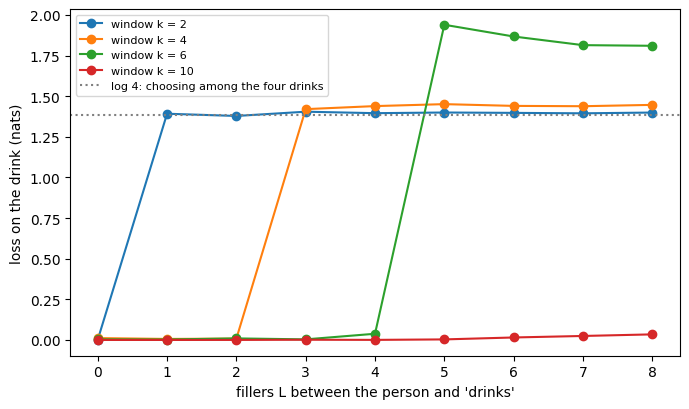

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for column in wall.columns:
    ax.plot(wall.index, wall[column], marker="o", label=column)
ax.axhline(np.log(4), color="gray", linestyle=":", label="log 4: choosing among the four drinks")
ax.set_xlabel("fillers L between the person and 'drinks'")
ax.set_ylabel("loss on the drink (nats)")
ax.legend(fontsize=8)
plt.tight_layout()

### A bigger window?

The natural answer is to increase $k$. We train the concatenation with $k$ from 5 to 8, next to the values for $k = 1, \dots, 4$ that we already have, and we look at the perplexity of the validation set.

k (words of memory),1,2,3,4,5,6,7,8
validation perplexity,63.9,47.6,44.0,42.7,42.2,42.1,41.9,42.1


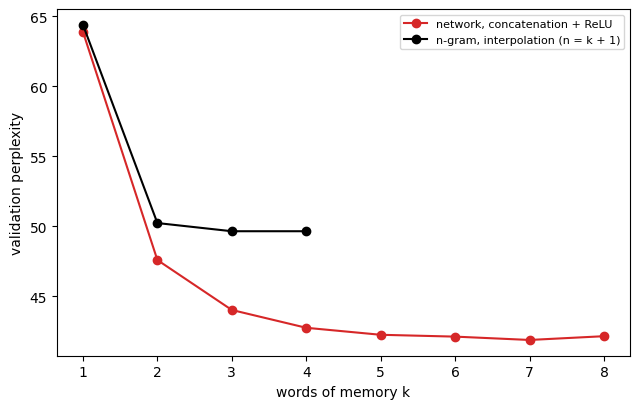

In [16]:
for k in (5, 6, 7, 8):
    networks["concatenation + ReLU", k], _ = fit_or_load("concatenation + ReLU", k, "concat", 128)
saturation = pd.Series({k: validation_perplexity("concatenation + ReLU", k) for k in range(1, 9)}, name="validation perplexity").rename_axis("k (words of memory)")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(saturation.index, saturation, marker="o", color="tab:red", label="network, concatenation + ReLU")
ax.plot(range(1, 5), [ngram_perplexity[k + 1] for k in range(1, 5)], marker="o", color="black", label="n-gram, interpolation (n = k + 1)")
ax.set_xlabel("words of memory k")
ax.set_ylabel("validation perplexity")
ax.legend(fontsize=8)
plt.tight_layout()
saturation.to_frame().T.style.format("{:.1f}")

The perplexity of the concatenation goes 63.9, 47.6, 44.0, 42.7, 42.2, 42.1, 41.9 and 42.1: after $k = 4$ the total gain is less than one point (and we have not tested whether it is real). We should be careful with the reading: the sentences of the recipes are short (9.9 words on average, see the table below), so that a window of 8 words covers almost all of them, and the saturation says little about dependencies that are farther. What the figure says is that the cost of a longer window is linear (the table of the parameters) and the **benefit is not**: increasing $k$ is not the answer. We did not train the same models on the plots of films, which have longer sentences, to keep the notebook short.

### What the network writes

Perplexity measures the probability of the words that are really there. As in the previous notebook, we let the networks write (drawing each word from the distribution of the network, so that they are not the pure counts of the previous notebook but a smoothed model) and we measure on 500 sentences for each model the same things: the share of **4-grams** of the generated text found in the training text, the share of sentences identical to a sentence of the training set, the mean length and the share of sentences that do not end within 30 words. The reference points are the real sentences of the validation set and the counting models of the previous notebook with the pure counts (the maximum likelihood estimate), of the same memory.

In [17]:
def four_grams(sentences):
    return {t for s in sentences for t in zip(s, s[1:], s[2:], s[3:])}

seen_sentences, seen_four_grams = set(train), four_grams(train)

def measures(sentences):
    return {"4-grams found in the training text": np.mean([t in seen_four_grams for s in sentences for t in zip(s, s[1:], s[2:], s[3:])]),
            "sentences identical to a training sentence": np.mean([s in seen_sentences for s in sentences]),
            "mean length (words)": np.mean([len(s) - 2 for s in sentences]),
            "reach 30 words": np.mean([len(s) - 2 >= 30 for s in sentences])}

as_sentence = lambda t: (vocabulary.start,) + tuple(t) + ((vocabulary.end,) if len(t) < 30 else ())
rows, examples = {"real sentences (validation set)": measures(validation)}, {}
for k in (2, 3, 4):
    rng = np.random.default_rng(0)
    texts = [ngrams[k + 1].generate(rng, method="mle") for _ in range(500)]
    rows[f"n-gram, n = {k + 1}, pure counts"] = measures([as_sentence(t) for t in texts])
    rng = np.random.default_rng(0)
    texts = [lm.generate_window(networks["concatenation + ReLU", k], vocabulary, rng) for _ in range(500)]
    rows[f"network, k = {k}"] = measures([as_sentence(t) for t in texts])
    examples[k] = [" ".join(vocabulary.decode(t)) for t in texts[:3]]
for k, texts in examples.items():
    print(f"network, k = {k}")
    for t in texts:
        print("   ", t)
pd.DataFrame(rows).T.style.format({"4-grams found in the training text": "{:.1%}", "sentences identical to a training sentence": "{:.1%}",
                                   "mean length (words)": "{:.1f}", "reach 30 words": "{:.1%}"})

network, k = 2
    using a to
    microwave pans for about minutes do not <unk> flavor <unk> don't remove any quarters with half
    add broth place one leaves typically drumsticks so that it will be quite thick
network, k = 3
    lightly golden
    to assemble sandwiches
    while rice simmers turn <unk> sweet
network, k = 4
    warm and add the ham patties and repeat with machine on <unk> which
    transfer to casserole drain the leaves
    add vegetables to your paste reheating power butter until heated through


,4-grams found in the training text,sentences identical to a training sentence,mean length (words),reach 30 words
real sentences (validation set),41.7%,14.6%,9.9,1.1%
"n-gram, n = 3, pure counts",59.3%,14.4%,9.8,0.0%
"network, k = 2",28.8%,11.0%,9.3,0.0%
"n-gram, n = 4, pure counts",100.0%,31.2%,9.3,0.0%
"network, k = 3",30.7%,10.4%,9.2,0.0%
"n-gram, n = 5, pure counts",100.0%,55.6%,9.9,0.0%
"network, k = 4",28.1%,8.8%,9.6,0.0%


**The network does not recite**: the sentences identical to a sentence of the training set are 11.0, 10.4 and 8.8% for $k = 2, 3, 4$, against 31.2% and 55.6% of the n-grams with $n = 4$ and $n = 5$ (14.6% in the real text). It does not even have the coherence of the n-gram, though: the share of its 4-grams found in the training text is 28.8, 30.7 and 28.1%, below the 41.7% of the real text, at the level of the n-gram with $n = 2$ (14.8% in the previous notebook) and far from the 59.3% of $n = 3$. The comparison is not between equals: the network draws among all the words of the vocabulary, with a smoothed distribution, while the pure counts draw only among the words that were seen after the context, and a 4-gram that is new is not necessarily a mistake.

The sentences confirm it. They are plausible in pieces and drift (`add vegetables to your paste reheating power butter until heated through`, `warm and add the ham patties and repeat with machine on <unk> which`), and some are fine (`while rice simmers turn <unk> sweet`, `to assemble sandwiches`). In all the models **no sentence reaches 30 words**, while 1.1% of the real ones do: the decision to end the sentence depends only on the last $k$ words, and nothing in the window says how long the sentence has already become.

In [18]:
rng = np.random.default_rng(3)
for k in (2, 4):
    model = networks["concatenation + ReLU", k]
    print(f"k = {k}, greedy:   ", " ".join(vocabulary.decode(lm.generate_window(model, vocabulary))))
    for _ in range(2):
        print(f"k = {k}, T = 0.5:  ", " ".join(vocabulary.decode(lm.generate_window(model, vocabulary, rng, temperature=0.5))))

k = 2, greedy:    add the chicken and cook until the mixture
k = 2, T = 0.5:   add the chopped green pepper and serve
k = 2, T = 0.5:   serve with a fork
k = 4, greedy:    add the tomatoes and cook until tender
k = 4, T = 0.5:   heat oil in a large frying pan
k = 4, T = 0.5:   transfer to a greased baking sheet and cover with foil


With the greedy choice the network gives the most typical sentence (`add the chicken and cook until the mixture`, `add the tomatoes and cook until tender`), and with temperature 0.5 the sentences are regular and generic.

What we have is a text that is **locally plausible and with no plan**: every word depends on the $k$ before it, nothing keeps what the sentence is about, nor how it will end, and the model does not know that the sentence before exists (the sentences are independent in our data). The window of fixed size cannot do it.

## The test set

As in the previous notebooks, we choose on the validation set and we look at the test set **once**. We take the window $k$ with the lowest validation perplexity of the concatenation with ReLU, among the ones that we trained (the smaller one when two are equal to the first decimal), and the weight $\lambda$ of the mixture with the 4-gram model is the one fitted on the validation set. The test set is used for the frequency of the words, the 4-gram model of the previous notebook, the network and the mixture.

In [19]:
k = min(saturation.index, key=lambda k: (round(saturation[k], 1), k))
model = networks["concatenation + ReLU", k]
ngram = ngrams[4]
weights = ngram.fit_weights(validation)

Xv, yv, _ = lm.windows(validation, k)
Xn, yn = ngram.positions(validation)
assert (yv == yn).all()
lam = fit_mixture(np.exp(lm.log_probabilities(model, Xv, yv)), ngram.probabilities(Xn, yn, method="interpolation", weights=weights))

Xt, yt, _ = lm.windows(test, k)
Xtn, ytn = ngram.positions(test)
assert (yt == ytn).all()
p_network = np.exp(lm.log_probabilities(model, Xt, yt))
p_ngram = ngram.probabilities(Xtn, ytn, method="interpolation", weights=weights)
pd.Series({"frequency of the words (n = 1)": ngrams[1].perplexity(test, method="mle"),
           "n-gram model, n = 4, interpolation": perplexity_of(p_ngram),
           f"network, concatenation + ReLU, k = {k}": perplexity_of(p_network),
           "mixture of the two": perplexity_of(lam * p_network + (1 - lam) * p_ngram)}, name="test perplexity").to_frame().style.format("{:.1f}")

,test perplexity
frequency of the words (n = 1),297.3
"n-gram model, n = 4, interpolation",47.3
"network, concatenation + ReLU, k = 7",40.1
mixture of the two,35.6


The window chosen on the validation set is $k = 7$ (41.9, against 42.7 for $k = 4$: the differences among the windows from 4 on are small and we have not tested them). On the test set the frequency of the words gives 297.3 and the 4-gram model 47.3, the numbers of the previous notebook. The network gives **40.1**, 15% less than the counts, and the mixture of the two (with the weight fitted on the validation set) **35.6**, 25% less. The ordering of the validation set is confirmed on a set that we have not used for any choice.

## What we have learned

- **The probability of the next word can be approximated by a function** with parameters shared among all the contexts. The embeddings make the words that are used in the same way behave in the same way: in the toy example the network answers 0.99 on a context never seen (`sara buys`), where the counts have no estimate and fall back to 31%.
- **The average of the embeddings loses the order**, and the permutation test shows it: the perplexity does not change when we shuffle the window (60.1), and it **grows** with the number of words (57.8, 60.1, 62.4 for $k = 2, 3, 4$ without the layer). **The concatenation keeps the positions**: 47.6, 44.0, 42.7 for the same $k$, and 299.1 after the shuffling.
- **At the same memory the network is better than the n-grams**: 44.0 against 49.6 in the recipes with $k = 3$ and $n = 4$ (validation set). Most of the gain is in the positions whose context was never seen (73.6 against 95.6), as the argument of generalization predicts.
- **Counting and the network are complementary**: the mixture gives 39.5 on the validation set and 35.6 on the test set, against 47.3 of the n-gram model.
- **The window is a wall.** The toy example shows it exactly (the loss is zero if the person is inside the window and it is a blind guess outside), and in the corpora in the recipes increasing $k$ gives a gain that saturates after $k = 4$.
- **The text has no plan.** The network does not recite as the n-grams with a lot of memory do (8.8 to 11.0% of the sentences are copies, 31.2% and 55.6% for the n-grams), but it does not write a coherent text either: the sentences are plausible in pieces, they do not know how long they are and none of them reaches the length of the longest real ones.

The model that we have built has two limits that come from the same choice: it **looks at a fixed number of words**, and **each position has its own weights**. What we want is a model that reads a sequence of any length, uses the same weights at each step, and keeps in a vector a **summary of everything it has read**, whatever the length. It is the subject of the next part of the course: first the recurrent networks, which do just that, and then the attention that lets the model choose which of the previous words to look at.

For the discussion: *(a)* with $k = 1$ the average with the layer and the concatenation are the same model. Why? And why is the shuffled window about as bad as no context at all (299.1 against 304.6)? *(b)* in the toy with the wall the network with $k = 6$ pays more than $\log 4$ when the person is out of the window. What could make it worse than a blind guess, and how would you check it? *(c)* the recipes gain almost nothing for $k > 4$. Would you expect the same on the plots of films, which have longer sentences, and which choices of this notebook (the size of the layer, the early stopping, the amount of data) would you change to find out? *(d)* the output layer has $V \times h$ weights and the softmax is computed on all the words: what happens with a vocabulary of 100,000 words, and which of the ideas of the notebook on Word2Vec would you use?